In [28]:
import pandas as pd
import numpy as np

In [29]:
df=pd.read_csv("powerplant_data.csv")

In [30]:
df

# AT-> Temperature
# V-> Vaccum
# AP-> Pressure
#RH-> Humidity

#PE-> produce energy/produce output

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43
...,...,...,...,...,...
9563,15.12,48.92,1011.80,72.93,462.59
9564,33.41,77.95,1010.30,59.72,432.90
9565,15.99,43.34,1014.20,78.66,465.96
9566,17.65,59.87,1018.58,94.65,450.93


In [31]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [32]:
X=df.drop("PE", axis=1)
y=df["PE"]

In [33]:
# train test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [34]:
# scaling

from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [35]:
import torch
import torch.nn as nn

X_train_tensor=torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values, dtype=torch.float32).view(-1,1)

X_test_tensor=torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [36]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset=TensorDataset(X_train_tensor, y_train_tensor)
test_dataset=TensorDataset(X_test_tensor, y_test_tensor)

In [37]:
train_loader=DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader=DataLoader(test_dataset, batch_size=32)

### Deep Learning

In [38]:
# Define our ANN model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model=nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),
    
            #2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),
    
            #Output
            nn.Linear(6, 1),

    )

    def forward(self, x):
        return self.model(x)

In [39]:
import torch.optim as optim

model=ANN()

# loss, optimizer
criterion=nn.MSELoss()
optimizer=optim.Adam(model.parameters())

In [43]:
# Train the ANN

train_losses=[]
val_losses=[]

best_val_loss=float("inf")
epochs=100

for epoch in range(epochs):
    model.train()
    running_loss=0.0  #total training loss for 1 epoch

    for xb, yb in train_loader:
        # xb-> features of 1 batch
        #yb-> labels/output of 1 batch

        optimizer.zero_grad()

        outputs=model(xb)        #forward prop...predicted outputs for this batch
        loss=criterion(outputs, yb) # compute loss
        loss.backward()   #back prop...compute gradients
        optimizer.step()   #param update
    
        running_loss+= loss.item()   #loss is a tensor=> to python float value 

    epoch_train_loss=running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)


    #validation
    model.eval()
    running_val_loss=0.0

    with torch.no_grad():
        for xb, yb in test_loader:
            outputs=model(xb)
            loss=criterion(outputs, yb)
            running_val_loss+=loss

    epoch_val_loss=running_val_loss/len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs}===> train loss {epoch_train_loss} & val loss={epoch_val_loss}")


    if epoch_val_loss< best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")  #.pt and .pth

epoch 1/100===> train loss 205705.04153645833 & val loss=203027.78125
epoch 2/100===> train loss 193914.99407552084 & val loss=179965.546875
epoch 3/100===> train loss 157141.43531901043 & val loss=130551.9453125
epoch 4/100===> train loss 101526.00426432291 & val loss=73906.765625
epoch 5/100===> train loss 53548.75620117188 & val loss=37687.5
epoch 6/100===> train loss 29446.87226155599 & val loss=23376.244140625
epoch 7/100===> train loss 20482.653767903645 & val loss=17821.244140625
epoch 8/100===> train loss 16321.74307454427 & val loss=14363.6357421875
epoch 9/100===> train loss 13034.828430175781 & val loss=11306.5341796875
epoch 10/100===> train loss 9881.155482991537 & val loss=8096.72900390625
epoch 11/100===> train loss 6859.482036336263 & val loss=5404.013671875
epoch 12/100===> train loss 4495.658464050293 & val loss=3444.9404296875
epoch 13/100===> train loss 2896.6946080525718 & val loss=2240.64453125
epoch 14/100===> train loss 1960.1140108744303 & val loss=1577.1568603

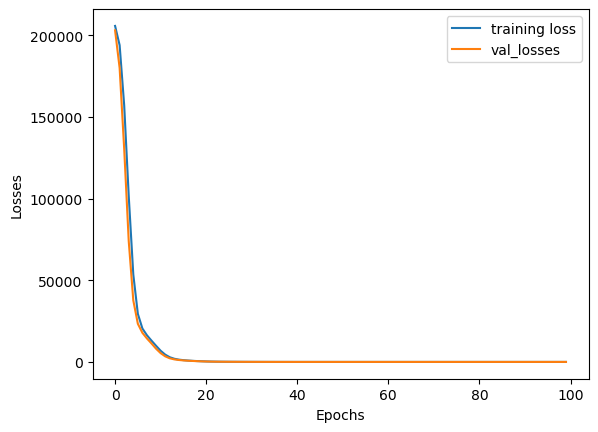

In [44]:
import matplotlib.pyplot as plt

loss_df=pd.DataFrame({
    "training_loss": train_losses,
    "val_losses": val_losses
})

plt.plot(loss_df["training_loss"], label="training loss")
plt.plot(loss_df["val_losses"], label="val_losses")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [45]:
# loading the best model

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [46]:
#evaluation

model.eval()
with torch.no_grad():
    train_preds=model(X_train_tensor)
    test_preds=model(X_test_tensor)

    train_mse_loss=criterion(train_preds, y_train_tensor)
    test_mse_loss=criterion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 18.973114013671875
Testing MSE: 17.330120086669922


In [47]:
from sklearn.metrics import r2_score

print("r2_score:", r2_score(y_test, test_preds))

r2_score: 0.9394357000201231


In [49]:
predicted_df=pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df=pd.DataFrame(y_test.values, columns=["Actual Values"])

pd.concat([predicted_df,actual_df], axis=1)

,Predicted Values,Actual Values
0,436.254883,433.27
1,436.328949,438.16
2,460.252655,458.42
3,476.450134,480.82
4,438.615845,441.41
...,...,...
1909,450.969055,456.70
1910,433.756439,438.04
1911,467.701233,467.80
1912,433.299927,437.14
